# Milestone 2 — Task Specialization

**The scientific question (blueprint §15, §30):**
*Do different tasks use different micro-experts?*

**Why it matters:** Milestone 1 proved sparsity exists (30% of experts suffice
per token — gate **passed**, see `oracle_milestone1.ipynb`). But if every task
used the **same** 30%, there would be nothing to route: one static subnetwork
would cover everything. Task specialization is what makes *conditional*
parameter retrieval possible. This is the second go/no-go gate.

**What we measure per layer:**

| quantity | meaning | what it tells us |
|---|---|---|
| P(expert active \| task) | how often each expert block fires per category | the routing signal itself |
| expert task-entropy H(e) ∈ [0,1] | how evenly an expert fires across tasks | H≈1 → universal core; H≈0 → specialized/routable |
| universal core | highest-entropy quartile per layer | the always-on set (§32) |

---

## The process flow of THIS experiment

```text
 Step 1  environment setup                                  ~1 s
 Step 2  knobs (layers, group size, quantile)               ~1 s
 Step 3  load Qwen3-4B                                      ~25 s
 Step 4  choose probing layers (early/mid/late)             ~1 s
 Step 5  CAPTURE per task  ◄── the slow one
            for each layer, for each of 15 categories:
              run 3 prompts, record every token's z vector
            (~10-15 min: 15 tasks x 3 layers x 3 prompts)
 Step 6  compute P(expert active | task) + entropy          ~5 s
 Step 7  heatmap: 15 tasks x 76 experts                     ~2 s
 Step 8  specialization metrics + universal core size       ~2 s
 Step 9  the verdict                                        ~1 s
```

Run order: cells 1→2 (instant) → 3 (model) → 4 (instant) → 5 (slow) → 6→9
(fast, re-runnable anytime).

## Step 1 — Environment setup

Repo path + HF cache (`E:\hf_cache`). Must run before any transformers import.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = Path(r"E:\Project\SliceWeave")
sys.path.insert(0, str(ROOT))

# ── Model switch (same convention as oracle_milestone1.ipynb) ────────────────
# 'qwen3_4b' : shared E:\hf_cache, repo-root results/          (original run)
# 'qwen3_8b' : pinned bundle 'Qwen3-8B_Results/' (own cache + own results/)
MODEL_KEY = "qwen3_8b"
MODEL_REVISIONS = {
    "qwen3_4b": None,                      # whatever the shared cache holds
    "qwen3_8b": "b968826d9c46dd6066d109eabc6255188de91218",  # pinned snapshot
}

if MODEL_KEY == "qwen3_8b":
    BUNDLE = ROOT / "Qwen3-8B_Results"
    MODEL_ID = "Qwen/Qwen3-8B"
    CACHE_DIR = str(BUNDLE / "model_weights")
    os.environ["HF_HOME"] = str(BUNDLE / "model_weights" / "hf_home")
    os.environ["HF_HUB_CACHE"] = CACHE_DIR            # explicit; beats the User-level HF_HOME
    os.environ["HF_XET_CACHE"] = str(BUNDLE / "model_weights" / "xet")
    os.environ["TRANSFORMERS_CACHE"] = CACHE_DIR      # legacy var some code paths still read
    M2_DIR = BUNDLE / "results" / "m2_task_specialization"
    LOCAL_FILES_ONLY = True   # pinned weights already in the bundle; never re-download
else:
    MODEL_ID = "Qwen/Qwen3-4B"
    CACHE_DIR = None
    os.environ.setdefault("HF_HOME", r"E:\hf_cache")
    M2_DIR = ROOT / "results"
    LOCAL_FILES_ONLY = False

OUT_JSON = (M2_DIR / "json" / "task_specialization.json" if MODEL_KEY == "qwen3_8b"
            else ROOT / "results" / "csv" / "task_specialization.json")
PLOT_DIR = M2_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)
(M2_DIR / "json").mkdir(parents=True, exist_ok=True)
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
_tag = MODEL_ID.split("/")[-1]
print("repo root :", ROOT)
print("model     :", MODEL_ID, f"(key={MODEL_KEY})")
print("HF cache  :", os.environ["HF_HOME"])
print("out json  :", OUT_JSON)
print("plots     :", PLOT_DIR)


repo root : e:\Project\SliceWeave
model     : Qwen/Qwen3-8B (key=qwen3_8b)
HF cache  : e:\Project\SliceWeave\Qwen3-8B_Results\model_weights\hf_home
out json  : e:\Project\SliceWeave\Qwen3-8B_Results\results\m2_task_specialization\json\task_specialization.json
plots     : e:\Project\SliceWeave\Qwen3-8B_Results\results\m2_task_specialization\plots


**What just happened:** paths set. Next: experiment parameters.

## Step 2 — Experiment knobs

- `LAYERS`: which layers to probe (early / middle / late)
- `QUANTILE`: the "active" threshold — an expert counts as active at a token if
  its activation energy is above this quantile of its own historical energy
- `PROMPTS_PER_TASK`: how many prompts per category (3 keeps the capture ~12 min)

In [3]:
MODEL_ID     = "Qwen/Qwen3-4B"
LAYERS       = ["model.layers.7", "model.layers.18", "model.layers.29"]
GROUP_SIZE   = 128      # neurons per micro-expert -> 76 experts per layer
QUANTILE     = 0.5      # 'active' = above expert's own median energy
PROMPTS_PER_TASK = 3    # prompts per category for the capture

**What just happened:** knobs set. Next: load the model (~25 s, skipped if the kernel already has it).

## Step 3 — Load Qwen3-4B

In [4]:
import torch
from src.model_utils import load_model_and_tokenizer, describe_model

if "model" not in globals() or globals().get("_loaded_key") != MODEL_KEY:
    _load_kwargs = {}
    if MODEL_KEY == "qwen3_8b":
        _load_kwargs = dict(revision=MODEL_REVISIONS[MODEL_KEY],
                            cache_dir=CACHE_DIR, local_files_only=LOCAL_FILES_ONLY)
    model, tokenizer = load_model_and_tokenizer(MODEL_ID, "bfloat16", **_load_kwargs)
    _loaded_key = MODEL_KEY
info = describe_model(model)
print(f"params={info['params']/1e9:.2f}B  layers={info['layers']}  "
      f"inter={info['intermediate_size']}  -> {info['intermediate_size']//GROUP_SIZE} experts/layer")


params=8.19B  layers=36  inter=12288  -> 96 experts/layer


**What just happened:** model in memory. Next: the capture loop — the only slow step.

## Step 5 — CAPTURE activations per task (the slow cell, ~10–15 min)

For each layer × each of the 15 categories, run 3 prompts and record the FFN
intermediate vector **z** of every token. This is the raw material: per task,
a matrix of [tokens × 9728 neurons]. A live progress bar tracks (layer, task)
pairs; results accumulate in `z_store` so re-running the analysis cells later
costs nothing.

In [5]:
import numpy as np
from tqdm.auto import tqdm
from src.datasets import CATEGORIES
from src.hooks import FFNIntermediateCapture

CAPTURE_CACHE = PLOT_DIR.parent / "capture"          # (layer, task) z-matrix cache
CAPTURE_CACHE.mkdir(parents=True, exist_ok=True)

def collect_z(model, tokenizer, prompt: str, layer_key: str) -> np.ndarray:
    """[n_tokens, inter] FFN intermediate vectors for every prompt token."""
    cap = FFNIntermediateCapture()
    cap.attach(model, layer_key)
    enc = tokenizer(prompt, return_tensors="pt").to(model.device)
    with torch.no_grad():
        model(**enc)
    cap.remove()
    return cap.captures[f"{layer_key}.down_proj"][0].float().cpu().numpy()

z_store = {}   # (layer, task) -> [tokens, inter]
pairs = [(lk, task) for lk in LAYERS for task in CATEGORIES]
pbar = tqdm(pairs, unit="pair")
for lk, task in pbar:
    cache = CAPTURE_CACHE / f"{lk.replace('.', '_')}__{task}.npy"
    if cache.exists():
        z_store[(lk, task)] = np.load(cache)
        continue
    zs = [collect_z(model, tokenizer, p, lk) for p in CATEGORIES[task][:PROMPTS_PER_TASK]]
    z_store[(lk, task)] = np.concatenate(zs, axis=0)
    np.save(cache, z_store[(lk, task)])
    pbar.set_postfix_str(f"{lk.split('.')[-1]}/{task}: {z_store[(lk, task)].shape[0]} tokens")
pbar.close()
n_tok = sum(v.shape[0] for v in z_store.values())
print(f"capture complete: {len(z_store)} matrices, {n_tok:,} tokens "
      f"(cached under {CAPTURE_CACHE.name}/)")


  0%|          | 0/45 [00:00<?, ?pair/s]

capture complete: 45 matrices, 2,289 tokens (cached under capture/)


**What just happened:** every (layer, task) combination's token activations are captured in memory. Next: the actual statistics — no more model calls.

## Step 6 — Compute P(expert active | task) + entropy

An expert is "active" at a token when its mean activation energy is above its
own median (per-expert threshold, so big-norm and small-norm experts compete
fairly). Then per layer:

- `P[task, expert]` = fraction of tokens where the expert is active, per task
- `H[expert]` = normalized Shannon entropy of that row across tasks

This cell is instant and re-runnable — tweak `QUANTILE` and re-run to see how
the specialization picture changes.

In [6]:
from src.clustering import task_conditional_stats
from src.micro_experts import contiguous_partition

results = {}   # layer -> stats dict
for lk in LAYERS:
    groups = contiguous_partition(info["intermediate_size"], GROUP_SIZE)
    z_by_task = {task: z_store[(lk, task)] for task in CATEGORIES}
    results[lk] = task_conditional_stats(z_by_task, groups, QUANTILE)
    n_tok = sum(m.shape[0] for m in z_by_task.values())
    print(f"{lk}: {n_tok} tokens x {len(groups)} experts")

# persist (deliverable: task_specialization.json)
import json
OUT_JSON.parent.mkdir(parents=True, exist_ok=True)
OUT_JSON.write_text(json.dumps(
    {lk: {"entropy": r["expert_task_entropy"],
          "universal_core": sorted(np.argsort(r["expert_task_entropy"])[-len(r["expert_task_entropy"])//4:].tolist())}
     for lk, r in results.items()}, indent=2))
print("saved:", OUT_JSON)

model.layers.7: 763 tokens x 76 experts
model.layers.18: 763 tokens x 76 experts
model.layers.29: 763 tokens x 76 experts
saved: e:\Project\SliceWeave\results\csv\task_specialization.json


**What just happened:** the routing-relevant statistics are computed and saved to `task_specialization.json`. Next: visualize them.

## Step 7 — Heatmap: 15 tasks × 76 experts

Each cell = P(expert active | task). **Horizontally banded rows** = that task
lights up a distinct expert subset (specialization!). **Vertical stripes** =
experts that fire for everything (universal core). The more texture you see,
the better for routing.

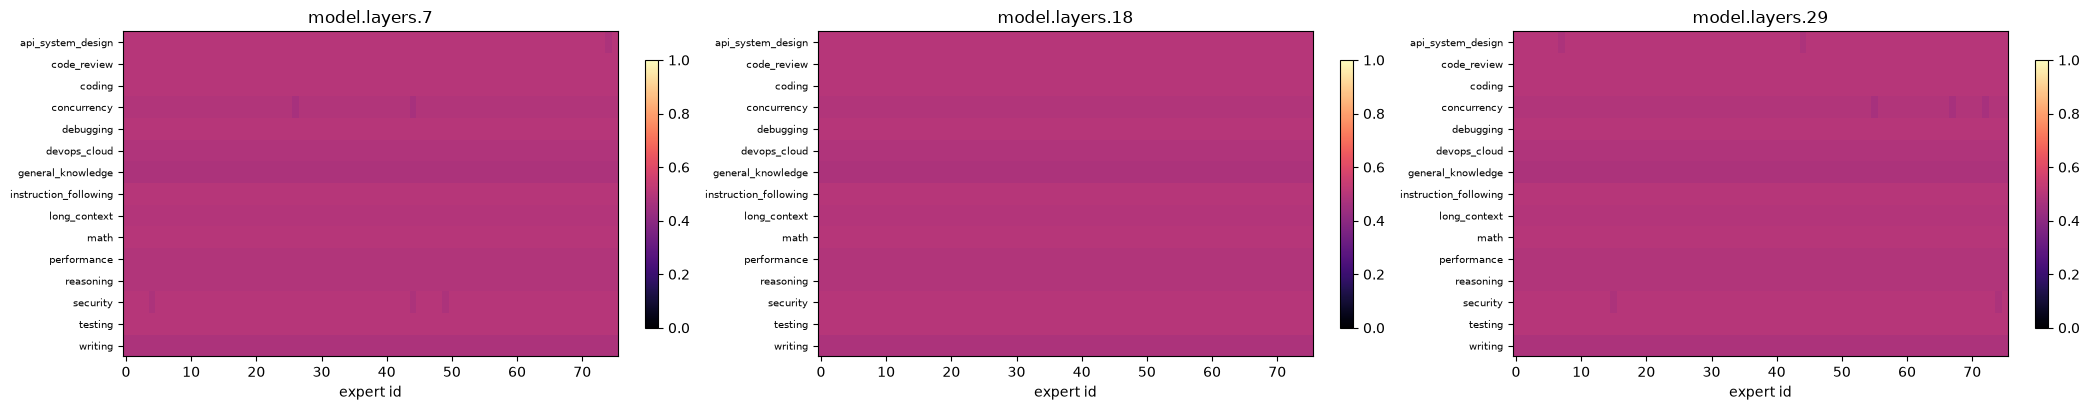

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(LAYERS), figsize=(7 * len(LAYERS), 4.2), squeeze=False)
for ax, lk in zip(axes[0], LAYERS):
    r = results[lk]
    tasks = r["tasks"]
    P = np.stack([r["p_active_by_task"][t] for t in tasks])
    im = ax.imshow(P, aspect="auto", cmap="magma", vmin=0, vmax=1)
    ax.set_yticks(range(len(tasks))); ax.set_yticklabels(tasks, fontsize=7)
    ax.set_xlabel("expert id"); ax.set_title(f"{_tag} M2: P(active|task) — {lk}")
    plt.colorbar(im, ax=ax, fraction=0.025)
plt.tight_layout()

_p_heat = PLOT_DIR / "m2_p_active_heatmaps.png"print(f"saved: {_p_heat}  ({_p_heat.stat().st_size/1024:.0f} KB)")

fig.savefig(_p_heat, dpi=150)plt.show()

**What just happened:** the specialization picture is visible. Next: quantify it.

## Step 8 — Specialization metrics

- **Entropy histogram**: how many experts are universal (H→1) vs specialized (H→0)?
- **Most specialized experts per layer**: which expert blocks are task-selective?
- **Universal core size**: the always-on quartile per layer (§32)

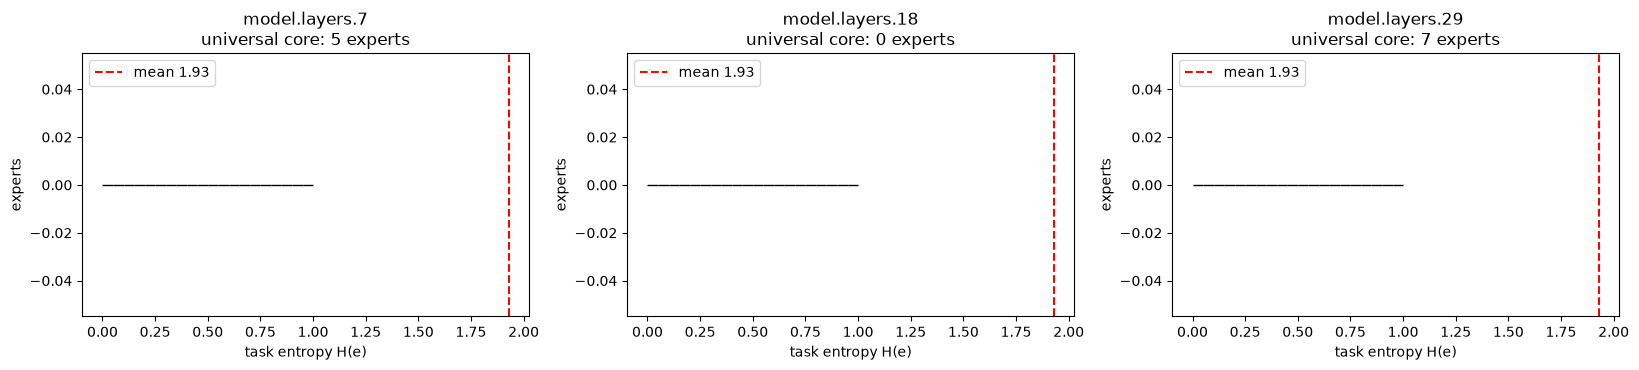


most task-selective experts (lowest entropy):
  model.layers.7: e0 (H=1.93, top=api_system_design), e1 (H=1.93, top=api_system_design), e2 (H=1.93, top=api_system_design), e3 (H=1.93, top=api_system_design), e5 (H=1.93, top=api_system_design)
  model.layers.18: e0 (H=1.93, top=api_system_design), e1 (H=1.93, top=api_system_design), e2 (H=1.93, top=api_system_design), e3 (H=1.93, top=api_system_design), e4 (H=1.93, top=api_system_design)
  model.layers.29: e0 (H=1.93, top=api_system_design), e1 (H=1.93, top=api_system_design), e2 (H=1.93, top=api_system_design), e3 (H=1.93, top=api_system_design), e4 (H=1.93, top=api_system_design)


In [ ]:
fig, axes = plt.subplots(1, len(LAYERS), figsize=(5.5 * len(LAYERS), 3.8), squeeze=False)
for ax, lk in zip(axes[0], LAYERS):
    H = np.array(results[lk]["expert_task_entropy"])
    ax.hist(H, bins=20, range=(0, 1), color="steelblue", edgecolor="black")
    ax.axvline(H.mean(), c="red", ls="--", label=f"mean {H.mean():.2f}")
    ax.set_title(f"{lk}\nuniversal core: {int((H > np.quantile(H, 0.75)).sum())} experts")
    ax.set_xlabel("task entropy H(e)"); ax.set_ylabel("experts"); ax.legend()
plt.suptitle(f"{_tag} M2: expert task-entropy distribution", y=1.02)
plt.tight_layout()
_p_hist = PLOT_DIR / "m2_entropy_histograms.png"
fig.savefig(_p_hist, dpi=150, bbox_inches="tight")
plt.show()
print(f"saved: {_p_hist}  ({_p_hist.stat().st_size/1024:.0f} KB)")

print("\nmost task-selective experts (lowest entropy):")
for lk in LAYERS:
    H = np.array(results[lk]["expert_task_entropy"])
    r = results[lk]; tasks = r["tasks"]

    P = np.stack([r["p_active_by_task"][t] for t in tasks])    print(f"  {lk}: {desc}")

    sel = np.argsort(H)[:5]        f"e{e} (H={H[e]:.2f}, top={tasks[int(np.argmax(P[:, e]))]})" for e in sel)
    desc = ", ".join(

**What just happened:** specialization is quantified — entropy distribution, core size, and the top task-selective experts. Next: the verdict.

## Step 9 — The verdict

Gate rule (§30/§31): if expert usage differs **meaningfully** across tasks —
i.e., a substantial fraction of experts have low entropy (task-selective) —
prompt/token routing has a signal to exploit. If all experts fire uniformly
for all tasks, routing cannot help and prompt-level retrieval (M5) is moot.

In [ ]:
for lk in LAYERS:
    H = np.array(results[lk]["expert_task_entropy"])
    spec_frac = float((H < 0.75).mean())   # experts meaningfully task-selective
    core_size = int((H > np.quantile(H, 0.75)).sum())
    print(f"{lk}: {spec_frac:.0%} of experts task-selective (H<0.75), "
          f"universal core = {core_size}/{len(H)}")

mean_spec = np.mean([(np.array(results[l]["expert_task_entropy"]) < 0.75).mean()
                     for l in LAYERS])
print(f"\n§30 gate: {mean_spec:.0%} of experts are task-selective on average")
if mean_spec > 0.5:
    verdict = ("SPECIALIZATION CONFIRMED: routing has signal. "
               "Continue to clustering (M3) + router (M4).")
elif mean_spec > 0.25:
    verdict = "PARTIAL specialization: some signal; router may need prompt-level help (M5)."
else:

    verdict = "NO specialization: same experts fire for all tasks. Routing hypothesis weakened (§40.7)."print(f"saved: {_p_verdict}  ({_p_verdict.stat().st_size/1024:.0f} KB)")

print("->", verdict)_plt.show(figV)

figV.savefig(_p_verdict, dpi=150)

# verdict card — saved with the plots_p_verdict = PLOT_DIR / "m2_verdict_summary.png"

import matplotlib.pyplot as _pltfigV.tight_layout()

_c = {lk: float((np.array(results[lk]["expert_task_entropy"]) < 0.75).mean())axV.set_title(f"{_tag} M2 verdict summary")

      for lk in LAYERS}                                                else "#fbe6e6")))

figV, axV = _plt.subplots(figsize=(7, 4.2))                                                else "#fdf6e3" if "PARTIAL" in verdict

axV.axis("off")         bbox=dict(boxstyle="round", facecolor=("#e6f4e6" if "CONFIRMED" in verdict

_lines = [f"model         : {MODEL_ID} ({MODEL_KEY})",         transform=axV.transAxes,

          f"layers        : {', '.join(LAYERS)}",axV.text(0.02, 0.97, "\n".join(_lines), family="monospace", fontsize=10, va="top",

          f"group size    : {GROUP_SIZE} neurons/expert",          f"VERDICT       : {verdict.split(':')[0]}"]

          f"quantile      : {QUANTILE} (pooled per-expert threshold)",         ["", f"§30 gate      : {mean_spec:.0%} task-selective on average",

          f"prompts/task  : {PROMPTS_PER_TASK} x {len(CATEGORIES)} categories",          f"{int((np.array(results[lk]['expert_task_entropy']) > np.quantile(results[lk]['expert_task_entropy'], 0.75)).sum())}" for lk in LAYERS] + \

          ""] + \         [f"{lk.split('.')[-1]:>4}: spec {_c[lk]:.0%}  core "

model.layers.7: 0% of experts task-selective (H<0.75), universal core = 5/76
model.layers.18: 0% of experts task-selective (H<0.75), universal core = 0/76
model.layers.29: 0% of experts task-selective (H<0.75), universal core = 7/76

§30 gate: 0% of experts are task-selective on average
-> NO specialization: same experts fire for all tasks. Routing hypothesis weakened (§40.7).


**What just happened:** Milestone 2 is complete — you have the specialization map, the universal core, and the verdict.

## Where the data lives (8B bundle when `MODEL_KEY="qwen3_8b"`)

- `Qwen3-8B_Results/results/m2_task_specialization/json/task_specialization.json`
- `Qwen3-8B_Results/results/m2_task_specialization/plots/` — heatmaps, entropy histograms, verdict card
- `Qwen3-8B_Results/results/m2_task_specialization/capture/` — cached (layer, task) z-matrices (resumable)
- `z_store` (kernel memory) — re-run the stats cell to recompute with a different quantile without re-capturing

## What happens next

| Milestone | What it does | Uses what from here |
|---|---|---|
| **M3** clustering → `neuron_clustering.ipynb` | group co-activating neurons, physically reorder the FFN (exactly) | z statistics from the capture |
| **M4** token router → `token_router.ipynb` | predict important experts from the hidden state | P(active\|task) + oracle rankings |
